In [155]:
import pandas as pd

In [156]:
df = pd.read_csv("../data/books.csv")

In [157]:
df.head()

,Title,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five


In [158]:
df.shape

(1000, 3)

In [159]:
df.columns

Index(['Title', 'Price', 'Rating'], dtype='object')

In [160]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Title   1000 non-null   object
 1   Price   1000 non-null   object
 2   Rating  1000 non-null   object
dtypes: object(3)
memory usage: 23.6+ KB


In [161]:
df.isnull().sum()

Title     0
Price     0
Rating    0
dtype: int64

In [162]:
df.duplicated().sum()

np.int64(0)

In [163]:
df['Price'] = df['Price'].str.replace("Â£" , "" , regex=False).str.replace("£" , "" , regex=False).str.strip().astype(float)

In [164]:
df.head()

,Title,Price,Rating
0,A Light in the Attic,51.77,Three
1,Tipping the Velvet,53.74,One
2,Soumission,50.10,One
3,Sharp Objects,47.82,Four
4,Sapiens: A Brief History of Humankind,54.23,Five


In [165]:
df['Price'].describe()

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64

In [166]:
df.loc[df['Price'].idxmax()]

Title     The Perfect Play (Play by Play #1)
Price                                  59.99
Rating                                 Three
Name: 648, dtype: object

In [167]:
df.loc[df['Price'].idxmin()]

Title     An Abundance of Katherines
Price                           10.0
Rating                          Five
Name: 638, dtype: object

In [168]:
df['Rating'].value_counts()

Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

In [169]:
df['Price'].mean()

np.float64(35.07035)

In [ ]:
df['Price'].median()

np.float64(35.980000000000004)

**DATA VISUALIZATION**

In [ ]:
import matplotlib.pyplot as plt

**Rating Distribution Bar Chart**

C:\Users\VARSHA\AppData\Local\Temp\ipykernel_4488\1889505901.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


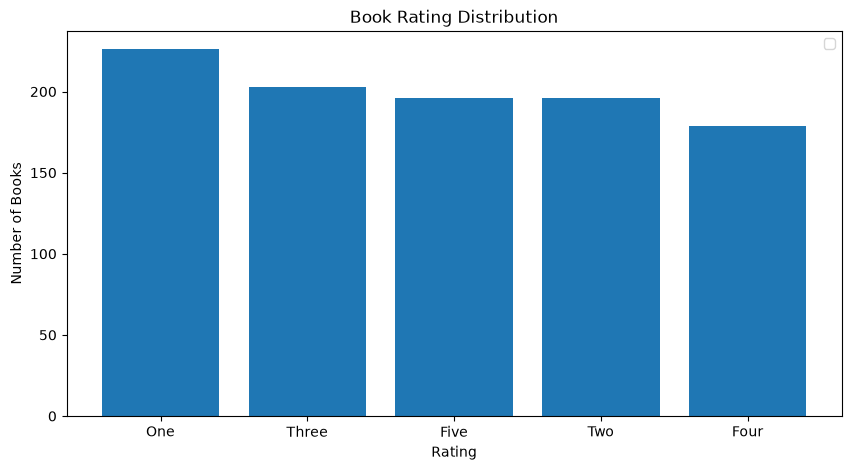

In [180]:
rating_counts = df['Rating'].value_counts()

plt.figure(figsize=(10,5))
plt.bar(rating_counts.index , rating_counts.values)
plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.legend()

plt.savefig("../visualizations/rating_distribution.png")
plt.show()

**Price Distribution**

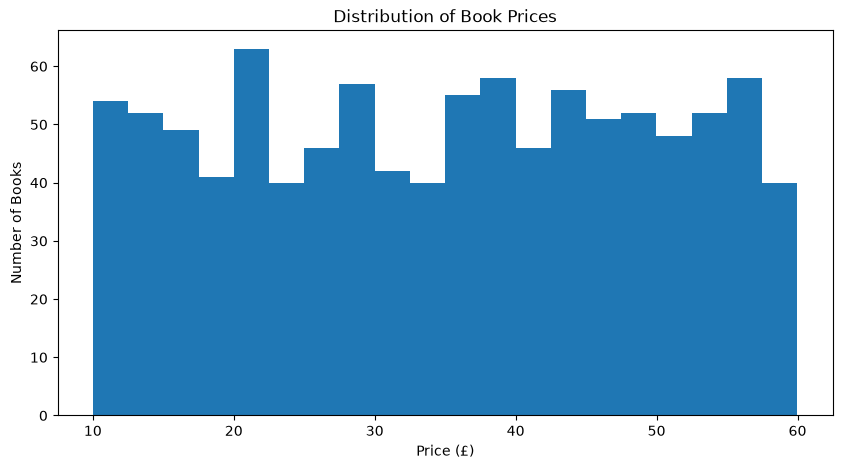

In [181]:
plt.figure(figsize=(10,5))
plt.hist(df['Price'] , bins=20)
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.savefig("../visualizations/price_distribution.png")
plt.show()

**Top 10 Most Expensive Books**

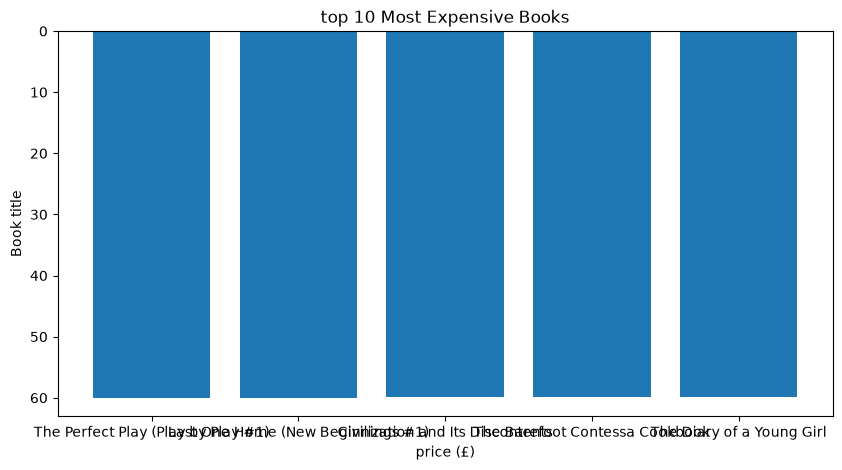

In [182]:
top_10 = df.sort_values("Price" , ascending=False).head()

plt.figure(figsize=(10,5))

plt.bar(top_10["Title"], top_10["Price"])

plt.title("top 10 Most Expensive Books")

plt.xlabel("price (£)")
plt.ylabel("Book title")

plt.gca().invert_yaxis()

plt.savefig("../visualizations/top_10_expensive_books.png")

plt.show()

**Rating vs Average Price**


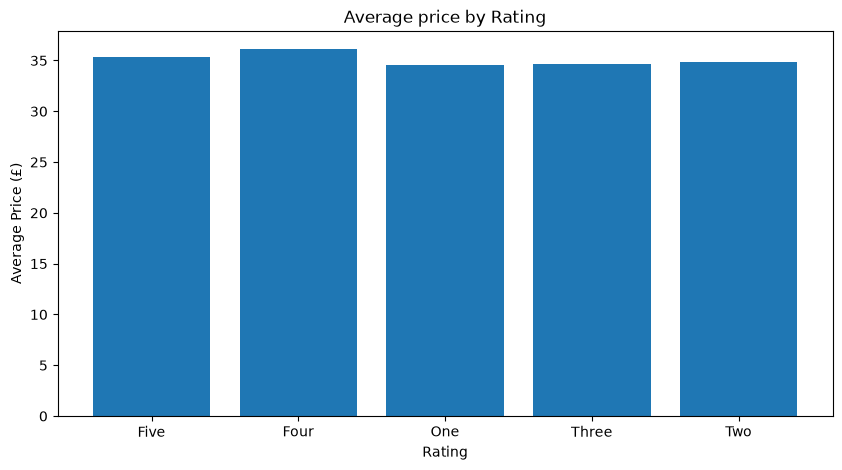

In [183]:
avg_price_rating = df.groupby("Rating")['Price'].mean()

plt.figure(figsize=(10,5))

plt.bar(avg_price_rating.index , avg_price_rating.values)

plt.title("Average price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price (£)")

plt.savefig("../visualizations/average_price_by_rating.png")
plt.show()